In [1]:
%matplotlib inline
%load_ext autoreload
%autoreload 2

# Psychophysical Kernel Analysis (Motion-Energy Based)

Expands on `2.13-psychophysical-kernal.ipynb` and `2.11-me-analysis.ipynb`. Goals:

1. Compute a **choice-conditioned, coherence-mean-subtracted** (residual) psychophysical kernel, which can use trials at every coherence. Show it next to the standard **0% coherence** kernel (Kiani et al. 2008; Nienborg & Cumming 2009; Okazawa et al. 2018), which needs no residualization. Note that the residual approach is our own extension: the cited papers use 0% coherence trials only. This replaces the outcome-conditioned kernel on raw motion energy in `2.13`.
2. Build the kernel hierarchically: trial -> session -> mouse -> group, so each of the mice contributes one data point to group statistics (not each of the ~25k trials pooled together).
3. Add real inferential statistics: bootstrap CI across mice + a cluster-mass permutation test for time windows where the kernel differs from zero.
4. Directly re-derive the **primacy effect** from ground-truth motion energy: pulse-triggered, choice-conditioned motion energy, split by pulse-timing bin (early/mid/late) x direction, to confirm -- using measured stimulus rather than nominal coherence/pulse bins -- that the choice-relevant impact of a pulse decays with latency (complements the pooled GLM in `1.0-psychometric-analysis.ipynb`).
5. Check replication across the two independent rigs/cohorts (UCLA vs UW, see `0.0-data-compilation.ipynb`).
6. Quantify the stimulus noise the kernels rely on. It is mostly a fixed per-trial bias ("hidden coherence"); test whether the mice weight it like nominal coherence.

Motion energy comes from `motion_energies_normalized/me_{type}.pkl` (written by `scripts/assemble_motion_energy.py`). It is mouse-tuned, cut at each trial's RT, sampled at 60 Hz on both rigs, and calibrated to **equivalent % coherence**, so kernels are in % coherence units. See `dissemination/reports/motion-energy-methods.md` and the caveats at the end.

## Setup

In [2]:
from pathlib import Path
import pickle
import warnings

import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

from notebooks.imports import *
from config import dir_config
from src.utils import scientific_plotting as spu

warnings.filterwarnings("ignore", category=UserWarning)
spu.setup()

raw_dir = Path(dir_config.data.raw)
processed_dir = Path(dir_config.data.processed)

# Figures for the manuscript/poster -- path relative to this notebook's location (notebooks/),
# not dir_config.project_dir (which resolves to the in-container "/src" path, not this repo checkout).
FIGURE_DIR = Path("../dissemination/figures")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

me_type = "global"  # "global", "center", or a quadrant key -- see notebooks/2.10-motion-energy-postprocessing.ipynb
RNG = np.random.default_rng(0)

## Load data

In [3]:
with open(Path(processed_dir, f"motion_energies_normalized/me_{me_type}.pkl"), "rb") as f:
    motion_energy_dict = pickle.load(f)

data = pd.read_csv(Path(processed_dir, "valid_data.csv"), index_col=None)
data["reaction_time"] = (data["reaction_time"] * 1000).astype(int)  # seconds -> ms
data = data[data["reaction_time"] < 3000].reset_index(drop=True)

# Two independent rigs/cohorts, encoded in the subject_id prefix (see notebooks/0.0-data-compilation.ipynb:
# "Data is collected from two different set of mice. 1. UCLA: Big screen, 2 pulse times 2. UW: smaller screen, 3 pulse times")
data["cohort"] = np.where(data["subject_id"].str.startswith("PSUIM"), "UCLA", "UW")

valid_keys = set(data["agg_code"].values)
motion_energy_dict = {k: v for k, v in motion_energy_dict.items() if k in valid_keys}
motion_energy_array = np.array([motion_energy_dict[k] for k in data["agg_code"].values])
assert len(motion_energy_array) == len(data), f"Length mismatch: {len(motion_energy_array)} vs {len(data)}"

# Motion energy is one sample per 60 Hz display frame on both rigs. (`framerate = 190` in scripts/ucla_rdk.py
# only scales dot velocity; UCLA pulse durations cluster at 50-51 ms = 3 frames at 60 Hz.)
FRAME_MS = 1000 / 60

print(f"{data['subject_id'].nunique()} mice, {data['idx_session'].nunique()} sessions, {len(data)} trials")
data.groupby("cohort")["subject_id"].nunique()

10 mice, 50 sessions, 21995 trials


cohort
UCLA    4
UW      6
Name: subject_id, dtype: int64

## Pulse-condition bookkeeping

In [4]:
pulse_mapping = {
    -3: "late_left_pulse", -2: "middle_left_pulse", -1: "early_left_pulse",
    0: "control",
    1: "early_right_pulse", 2: "middle_right_pulse", 3: "late_right_pulse",
}
pulse_time_bin_map = {1: "early", 2: "middle", 3: "late"}  # by |pulse_type|
pulse_dir_map = {-1: "left", 1: "right"}  # by sign(pulse_type)

data["pulse_condition"] = data["pulse_type"].map(pulse_mapping)
data["pulse_time_bin"] = data["pulse_type"].abs().map(pulse_time_bin_map)
data["pulse_direction"] = np.sign(data["pulse_type"]).map(pulse_dir_map)

# Control = no pulse seen before the response. Preprocessing (0.1) sets pulse_type = 0 when there was no pulse, when the
# pulse coherence equalled the base coherence, or when the response came before the pulse ended.
data["is_control"] = data["pulse_type"] == 0
print(f"{data['is_control'].sum()} control trials")

12421 control trials


## 1. Choice-conditioned, coherence-mean-subtracted kernel

The raw psychophysical kernel (mean ME for right choices minus mean ME for left choices, as in `2.13`) is
confounded by nominal coherence: the physical stimulus already differs systematically between rightward-
and leftward-choice trials whenever `|coherence| > 0`, since higher coherence drives both more motion
energy in that direction *and* more choices in that direction. The standard fix (Kiani et al. 2008;
Nienborg & Cumming 2009; Okazawa et al. 2018) is to use 0% coherence trials only. To use every trial, we
also compute a residual kernel (our own extension, not the method of those papers):

1. Compute, per `signed_coherence` condition (within a session), the mean ME trace across all trials of
   that condition -- the "expected" stimulus.
2. Subtract it from each trial's ME trace to get a noise residual that is, by construction, uncorrelated
   with nominal coherence.
3. Average residuals split by choice -- the resulting kernel reflects only the stimulus fluctuations that
   covary with choice, not the average signal strength.

We use control trials only (`is_control`: no pulse seen before the response), so a pulse never contaminates this baseline
kernel. Three kernels are computed so they can be compared directly: raw ME on all coherences (confounded,
shown for reference), residual ME on all coherences, and raw ME on 0% coherence trials. The last two should
agree in shape if the residual approach is sound.

In [5]:
def right_align_rows_with_nan_padding(arr):
    result = np.full_like(arr, np.nan, dtype=float)
    for i, row in enumerate(arr):
        valid = row[~np.isnan(row)]
        if len(valid):
            result[i, -len(valid):] = valid
    return result


def trim_by_nan_fraction(arr, threshold=0.4, from_end=False):
    """Drop leading/trailing time bins where more than `threshold` of rows are NaN.

    from_end=False trims the tail (for stimulus-onset-aligned data, where NaNs accumulate
    late as shorter-RT trials run out of frames). from_end=True trims the head (for
    response-onset-aligned / right-aligned data, where NaNs accumulate early).
    """
    nan_ratio = np.isnan(arr).mean(axis=0)
    over = np.where(nan_ratio > threshold)[0]
    if len(over) == 0:
        return arr
    cut = over[-1] + 1 if from_end else over[0]
    return arr[:, cut:] if from_end else arr[:, :cut]


def residual_motion_energy(me, signed_coherence):
    """Subtract, per signed-coherence condition, the condition-mean ME trace from each trial."""
    residual = np.full_like(me, np.nan, dtype=float)
    for coh in np.unique(signed_coherence):
        mask = signed_coherence == coh
        cond_mean = np.nanmean(me[mask], axis=0)
        residual[mask] = me[mask] - cond_mean
    return residual


def session_kernel(me, choice, alignment="stimulus_onset", nan_threshold=0.5):
    """Right-choice minus left-choice mean ME (or residual-ME) trace for one session.

    `choice` is coded 1 = rightward, 0 = leftward (checked: choice follows the sign of coherence).
    """
    me = me.copy()
    # align first, then blank sparse time bins: blanking before right-alignment would align long trials to
    # the blanking cutoff instead of to their response
    if alignment == "response_onset":
        me = right_align_rows_with_nan_padding(me)
    drop_cols = np.isnan(me).mean(axis=0) > nan_threshold
    me[:, drop_cols] = np.nan
    right = me[choice == 1]
    left = me[choice == 0]
    if len(right) == 0 or len(left) == 0:
        return np.full(me.shape[1], np.nan)
    return np.nanmean(right, axis=0) - np.nanmean(left, axis=0)

In [6]:
def build_hierarchical_kernels(df, me_array, use_residual, alignment, zero_coherence_only=False, nan_threshold=0.5, trim_threshold=0.4):
    """session -> mouse -> group kernel, so group stats treat each mouse as one sample."""
    session_rows = []
    for idx in df["idx_session"].unique():
        mask = (df["idx_session"] == idx).values & df["is_control"].values
        if zero_coherence_only:
            mask &= (df["signed_coherence"] == 0).values
        if mask.sum() < 10:
            continue
        sub = df.loc[mask]
        me = me_array[mask]
        if use_residual:
            me = residual_motion_energy(me, sub["signed_coherence"].values)
        kernel = session_kernel(me, sub["choice"].values, alignment=alignment, nan_threshold=nan_threshold)
        session_rows.append({
            "idx_session": idx,
            "subject_id": sub["subject_id"].iloc[0],
            "cohort": sub["cohort"].iloc[0],
            "kernel": kernel,
        })

    session_df = pd.DataFrame(session_rows)

    max_len = max(len(k) for k in session_df["kernel"])

    def pad(k):
        if alignment == "response_onset":
            return np.pad(k, (max_len - len(k), 0), constant_values=np.nan)
        return np.pad(k, (0, max_len - len(k)), constant_values=np.nan)

    session_mat = np.vstack(session_df["kernel"].apply(pad).values)

    mouse_rows = []
    session_df = session_df.assign(row=range(len(session_df)))
    for subj, sub in session_df.groupby("subject_id"):
        rows = sub["row"].values
        mouse_rows.append({
            "subject_id": subj,
            "cohort": sub["cohort"].iloc[0],
            "kernel": np.nanmean(session_mat[rows], axis=0),
        })
    mouse_df = pd.DataFrame(mouse_rows)
    mouse_mat = np.vstack(mouse_df["kernel"].values)
    mouse_mat = trim_by_nan_fraction(mouse_mat, threshold=trim_threshold, from_end=(alignment == "response_onset"))

    return session_df, session_mat, mouse_df, mouse_mat


KERNEL_TYPES = {  # name: (use_residual, zero_coherence_only)
    "raw": (False, False),
    "residual": (True, False),
    "zero_coh": (False, True),
}
kernels = {}
for name, (use_residual, zero_only) in KERNEL_TYPES.items():
    for alignment in ("stimulus_onset", "response_onset"):
        kernels[(name, alignment)] = build_hierarchical_kernels(data, motion_energy_array, use_residual, alignment, zero_coherence_only=zero_only)

{k: v[3].shape for k, v in kernels.items()}

{('raw', 'stimulus_onset'): (10, 75),
 ('raw', 'response_onset'): (10, 75),
 ('residual', 'stimulus_onset'): (10, 75),
 ('residual', 'response_onset'): (10, 75),
 ('zero_coh', 'stimulus_onset'): (10, 78),
 ('zero_coh', 'response_onset'): (10, 78)}

## 2. Group-level statistics: bootstrap CI + cluster-mass permutation test

Each mouse contributes exactly one kernel (averaged over its own sessions), so N = number of mice is the
correct sample size for inference here -- not the trial count. We bootstrap across mice for a 95% CI band,
and run a cluster-mass sign-flip permutation test to find contiguous time windows where the group kernel
differs significantly from zero, correcting for the multiple-comparisons problem across time points. This
is a minimal from-scratch implementation with no new dependency; swap in
`mne.stats.permutation_cluster_1samp_test` for a more standard/citable version if `mne` is an acceptable
addition to `pyproject.toml`.

In [7]:
def bootstrap_ci(mouse_mat, n_boot=5000, ci=95, rng=RNG):
    n = mouse_mat.shape[0]
    boot_means = np.full((n_boot, mouse_mat.shape[1]), np.nan)
    for b in range(n_boot):
        sample = rng.integers(0, n, n)
        boot_means[b] = np.nanmean(mouse_mat[sample], axis=0)
    lo, hi = np.nanpercentile(boot_means, [(100 - ci) / 2, 100 - (100 - ci) / 2], axis=0)
    return lo, hi


def cluster_permutation_test(mouse_mat, n_perm=2000, alpha=0.05, rng=RNG):
    """Sign-flip cluster-mass permutation test of the mouse-level kernel against zero."""
    n, t = mouse_mat.shape
    crit_t = stats.t.ppf(1 - alpha / 2, n - 1)

    def cluster_masses(tvals):
        sig = np.abs(tvals) > crit_t
        masses, run_start = [], None
        for i, s in enumerate(np.append(sig, False)):
            if s and run_start is None:
                run_start = i
            elif not s and run_start is not None:
                masses.append((run_start, i, np.nansum(np.abs(tvals[run_start:i]))))
                run_start = None
        return masses

    obs_t, _ = stats.ttest_1samp(mouse_mat, 0, axis=0, nan_policy="omit")
    obs_clusters = cluster_masses(obs_t)

    signs = rng.choice([-1, 1], size=(n_perm, n))
    max_null = np.zeros(n_perm)
    for p in range(n_perm):
        t_perm, _ = stats.ttest_1samp(mouse_mat * signs[p][:, None], 0, axis=0, nan_policy="omit")
        masses = cluster_masses(t_perm)
        max_null[p] = max((m for *_, m in masses), default=0)

    sig_clusters = []
    for s, e, m in obs_clusters:
        p_val = (np.sum(max_null >= m) + 1) / (n_perm + 1)
        if p_val < alpha:
            sig_clusters.append((s, e, p_val))
    return obs_t, sig_clusters

## 3. Plot: raw vs. residual vs. 0% coherence kernel, stimulus- and response-aligned

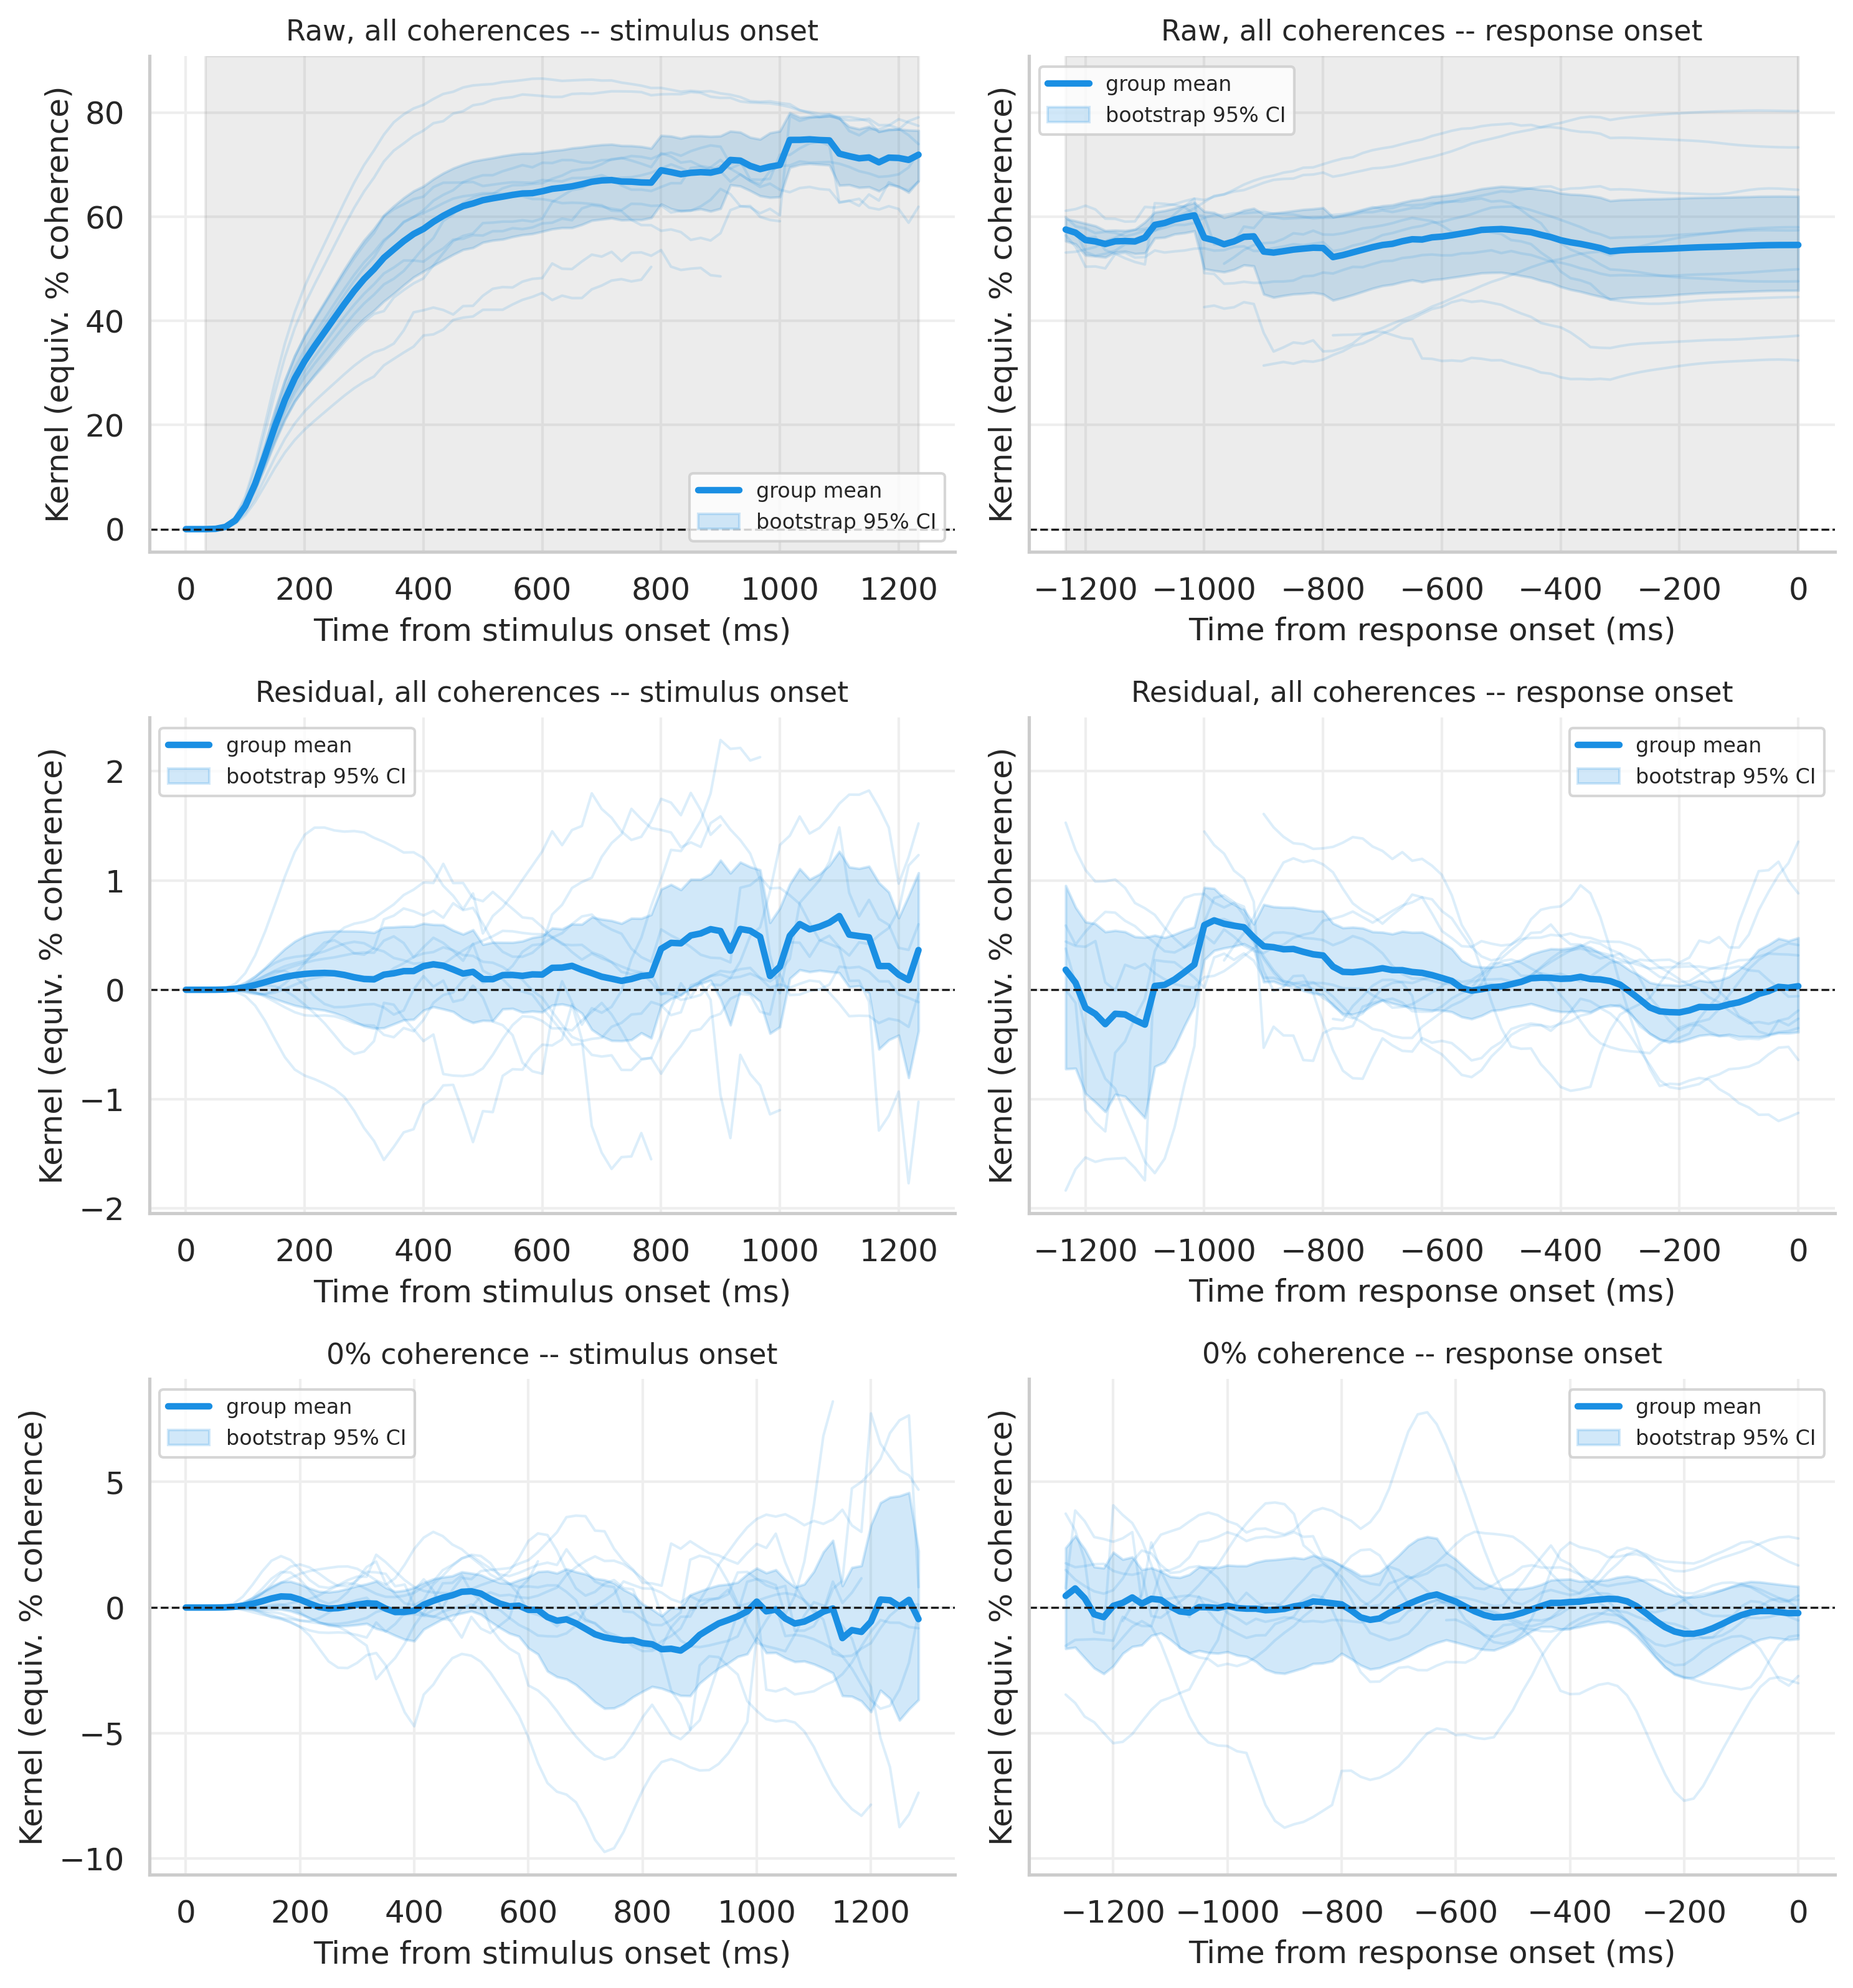

In [8]:
def time_axis(n, alignment, frame_ms=FRAME_MS):
    t = np.arange(n) * frame_ms
    return t if alignment == "stimulus_onset" else t - t[-1]


def plot_kernel_panel(ax, mouse_mat, alignment, title, color="#1a8fe3"):
    t = time_axis(mouse_mat.shape[1], alignment)
    lo, hi = bootstrap_ci(mouse_mat)
    mean = np.nanmean(mouse_mat, axis=0)
    _, sig_clusters = cluster_permutation_test(mouse_mat)

    ax.plot(t, mouse_mat.T, color=color, alpha=0.15, lw=1)
    ax.plot(t, mean, color=color, lw=2.5, label="group mean")
    ax.fill_between(t, lo, hi, color=color, alpha=0.2, label="bootstrap 95% CI")
    for s, e, p in sig_clusters:
        ax.axvspan(t[s], t[min(e, len(t) - 1)], color="grey", alpha=0.15)
    ax.axhline(0, color="k", lw=0.8, ls="--")
    ax.set_title(title, fontsize=11)
    ax.set_xlabel(f"Time from {'stimulus' if alignment == 'stimulus_onset' else 'response'} onset (ms)")
    ax.set_ylabel("Kernel (equiv. % coherence)")
    ax.legend(fontsize=8)


KERNEL_LABELS = {"raw": "Raw, all coherences", "residual": "Residual, all coherences", "zero_coh": "0% coherence"}
fig, axs = plt.subplots(3, 2, figsize=(spu.TEXTWIDTH * 1.4, spu.TEXTWIDTH * 1.5), sharey="row")
for row, name in enumerate(KERNEL_TYPES):
    for col, alignment in enumerate(("stimulus_onset", "response_onset")):
        _, _, _, mouse_mat = kernels[(name, alignment)]
        plot_kernel_panel(axs[row, col], mouse_mat, alignment, f"{KERNEL_LABELS[name]} -- {alignment.replace('_', ' ')}")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "psychophysical_kernel_raw_vs_residual.png", dpi=300)
plt.show()

## 4. Cohort replication check (UCLA vs UW)

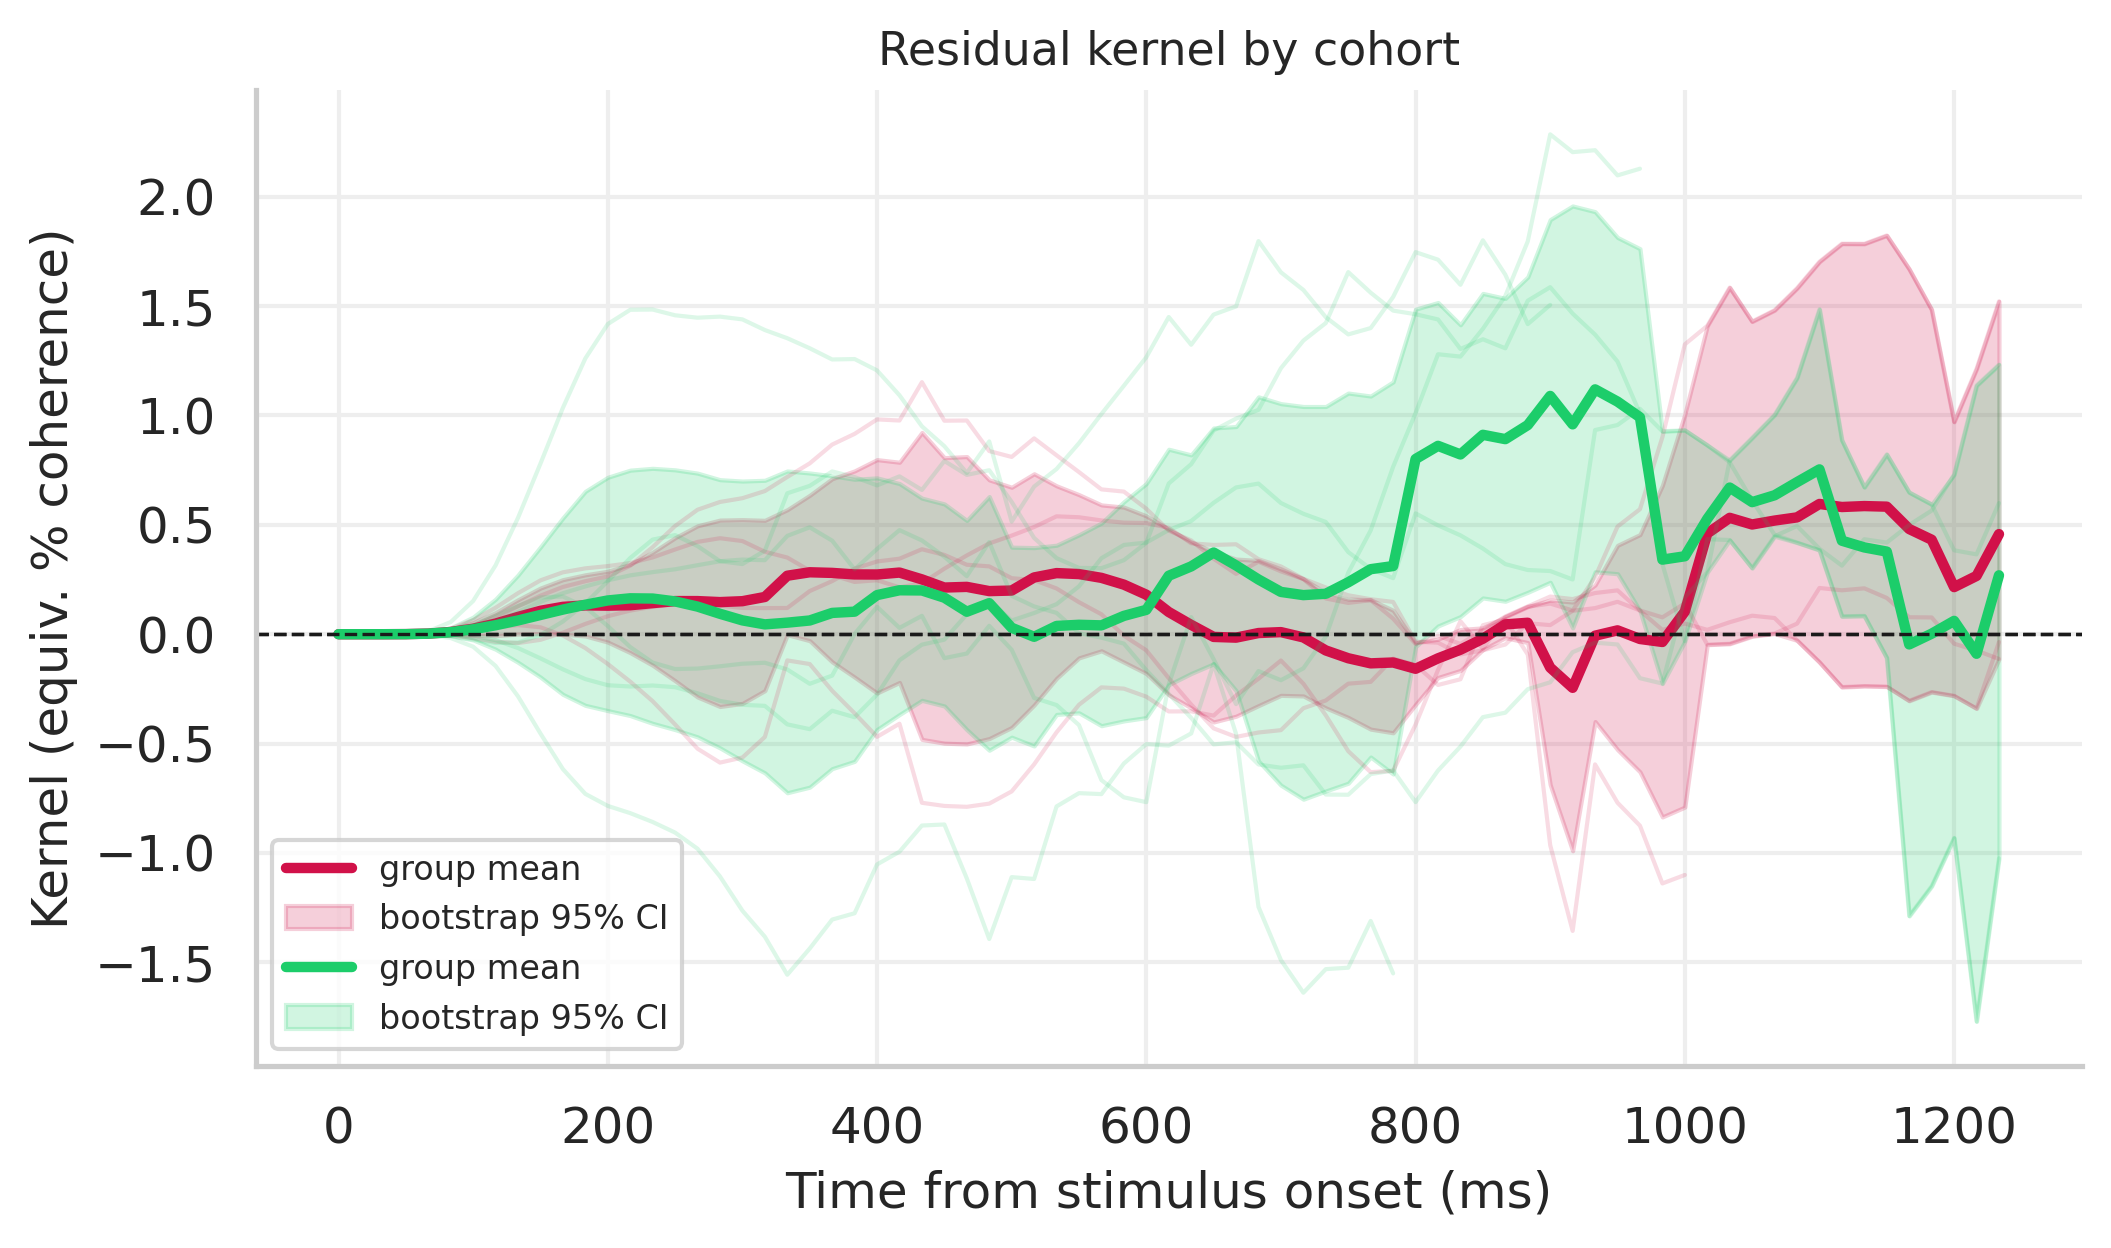

UCLA (n=4) mean amp=0.442, UW (n=6) mean amp=0.643, Mann-Whitney p=0.914


In [9]:
_, _, mouse_df, mouse_mat = kernels[("residual", "stimulus_onset")]

fig, ax = plt.subplots(figsize=(spu.TEXTWIDTH, spu.TEXTWIDTH * 0.6))
for cohort, color in zip(("UCLA", "UW"), ("#d11149", "#1ccd6a")):
    sub_mat = mouse_mat[mouse_df["cohort"].values == cohort]
    plot_kernel_panel(ax, sub_mat, "stimulus_onset", "Residual kernel by cohort", color=color)
plt.tight_layout()
plt.show()

# Simple two-group check on a scalar summary (peak |kernel| in the first 300ms) -- n is small (~5
# mice/cohort) so treat this as a replication sanity check, not a well-powered equivalence test.
window = slice(0, int(300 / FRAME_MS))
amp = np.nanmax(np.abs(mouse_mat[:, window]), axis=1)
ucla_amp = amp[mouse_df["cohort"].values == "UCLA"]
uw_amp = amp[mouse_df["cohort"].values == "UW"]
u_stat, p_val = stats.mannwhitneyu(ucla_amp, uw_amp)
print(f"UCLA (n={len(ucla_amp)}) mean amp={ucla_amp.mean():.3f}, UW (n={len(uw_amp)}) mean amp={uw_amp.mean():.3f}, Mann-Whitney p={p_val:.3f}")

## 5. Hidden coherence: the stimulus noise is a fixed bias per trial

In both rigs' RDKs (`scripts/ucla_rdk.py`, `scripts/uw_rdk.py`), each non-coherent dot draws a random direction at
stimulus onset and **keeps it for the whole trial**; only its position resets when its lifetime ends. Each seed therefore
carries a fixed net motion bias, the **hidden coherence**: the net rightward motion of all dots beyond the nominal
coherence (`scripts.motion_energy.hidden_coherence`). Effective coherence = nominal + hidden. It is zero at 100% coherence
and largest at 0% (all dots are noise), and it is larger on UW, which has fewer dots (~152 vs ~505).

Consequences:
- On 0% coherence trials, the "noise" in motion energy is mostly this one number per trial, not moment-to-moment
  fluctuation. ME noise stays correlated for seconds, so noise-based kernels (sections 1-3) cannot show *when* evidence
  is weighted. This differs from the dynamic random dots of Kiani et al. (2008), whose 0% coherence kernels could separate
  early from late weighting. Timing questions must be answered with the pulses (section 6).
- Hidden coherence is a clean per-trial regressor for sensitivity to stimulus noise. Below we check that it matches the
  motion energy, then test whether mice weight it like nominal coherence.

All valid trials are used here (no RT filter), because only the choice and the stimulus at onset matter. Pulses
change dot directions mid-trial, so only control trials are analysed.

Hidden coherence is saved to `<processed>/hidden_coherence.csv` (all trials, keyed by `agg_code`) for the GLM and DDM.
In the DDM, the motion energy input already contains this bias.

In [10]:
from scripts.motion_energy import hidden_coherence
from scripts.ucla_rdk import DotMotionStim
from scripts.uw_rdk import RandomDotMotion
import statsmodels.api as sm

all_trials = pd.read_csv(Path(processed_dir, "valid_data.csv"), index_col=None)
rdks = {"ucla": DotMotionStim(), "uw": RandomDotMotion()}
all_trials["hidden_coherence"] = [
    hidden_coherence(rig, rdks[rig], seed, coh)
    for rig, seed, coh in zip(all_trials["data_source"], all_trials["stimulus_seed"], all_trials["signed_coherence"])
]
all_trials["effective_coherence"] = all_trials["signed_coherence"] + all_trials["hidden_coherence"]
all_trials[["agg_code", "hidden_coherence", "effective_coherence"]].to_csv(Path(processed_dir, "hidden_coherence.csv"), index=False)

all_trials["is_control"] = all_trials["pulse_type"] == 0  # no pulse seen before the response (see 0.1)
# The full 5 s replay of a control trial still contains a scheduled pulse that came after the response; exclude those
# trials wherever the full replay is averaged (section 5a).
all_trials["replay_has_pulse"] = all_trials["is_pulse_trial"] & (all_trials["pulse_coherence"] != all_trials["signed_coherence"])
all_trials["cohort"] = np.where(all_trials["data_source"] == "ucla", "UCLA", "UW")
controls = all_trials[all_trials["is_control"]].copy()

print("SD of hidden coherence (% coherence), control trials:")
controls.pivot_table(index="signed_coherence", columns="cohort", values="hidden_coherence", aggfunc="std").round(2)

SD of hidden coherence (% coherence), control trials:


cohort,UCLA,UW
signed_coherence,,
-100,0.00,0.00
-36,2.48,4.65
-18,2.91,4.90
-9,2.97,5.59
0,3.29,5.82
9,3.01,5.69
18,2.85,5.22
36,2.55,4.72
100,0.00,0.00


### 5a. Hidden coherence explains the motion-energy noise

Correlation between hidden coherence and each trial's mean motion energy (333 ms to 5 s, full replay, not cut at the
RT) on 0% coherence trials, and autocorrelation of the ME noise. Trials whose replay contains a scheduled pulse after the response
are excluded here.

In [11]:
me_full = np.load(Path(processed_dir, "motion_energy_mouse/me_calibrated.npz"))
me_row = pd.Series(np.arange(len(me_full["agg_code"])), index=me_full["agg_code"])
lags_ms = [100, 250, 500, 1000, 2000]

for cohort, sub in controls[(controls["signed_coherence"] == 0) & ~controls["replay_has_pulse"]].groupby("cohort"):
    me = me_full[me_type][me_row[sub["agg_code"]].values][:, 20:300]
    r = np.corrcoef(sub["hidden_coherence"], me.mean(axis=1))[0, 1]
    noise = me - me.mean(axis=0)
    autocorr = [np.corrcoef(noise[:, :-lag].ravel(), noise[:, lag:].ravel())[0, 1] for lag in (round(l / FRAME_MS) for l in lags_ms)]
    print(f"{cohort}: n={len(sub)}, corr(hidden coherence, trial-mean ME) = {r:.2f}; "
          f"ME noise autocorrelation at {lags_ms} ms = {np.round(autocorr, 2).tolist()}")

UCLA: n=872, corr(hidden coherence, trial-mean ME) = 0.87; ME noise autocorrelation at [100, 250, 500, 1000, 2000] ms = [0.77, 0.46, 0.25, 0.18, 0.22]
UW: n=443, corr(hidden coherence, trial-mean ME) = 0.97; ME noise autocorrelation at [100, 250, 500, 1000, 2000] ms = [0.83, 0.63, 0.6, 0.6, 0.6]


In [12]:
# Does the motion-energy model weight hidden coherence like nominal coherence? (1.0 = same as nominal, by calibration)
import statsmodels.formula.api as smf

for cohort, sub in controls[(controls["signed_coherence"].abs() < 100) & ~controls["replay_has_pulse"]].groupby("cohort"):
    sub = sub.assign(me=me_full[me_type][me_row[sub["agg_code"]].values][:, 20:300].mean(axis=1))
    fit = smf.ols("me ~ C(signed_coherence) + hidden_coherence", sub).fit()
    print(f"{cohort}: ME per 1% hidden coherence = {fit.params['hidden_coherence']:.2f} +- {fit.bse['hidden_coherence']:.2f}")

UCLA: ME per 1% hidden coherence = 1.06 +- 0.01
UW: ME per 1% hidden coherence = 1.06 +- 0.01


### 5b. Do choices follow hidden coherence as the psychometric slope predicts?

If mice treat hidden coherence like nominal coherence, then on 0% coherence trials the mean hidden coherence should differ
between right and left choices by about `var(hidden) * p'(0) / (p (1 - p))`, where `p'(0)` is the psychometric slope at
0% (from a logistic-with-lapse fit to |coherence| <= 18%) and `p` is the fraction of right choices.

In [13]:
from scipy.optimize import curve_fit


def psychometric(c, beta, alpha, lapse):
    return lapse + (1 - 2 * lapse) / (1 + np.exp(-(beta * c + alpha)))


rows = []
for cohort, sub in controls.groupby("cohort"):
    low = sub[sub["signed_coherence"].abs() <= 18]
    (beta, alpha, lapse), _ = curve_fit(psychometric, low["signed_coherence"], low["choice"], p0=[0.05, 0, 0.05], bounds=([0, -5, 0], [1, 5, 0.45]))
    slope0 = (1 - 2 * lapse) * beta / 4  # dP(right)/dc at c = 0, per % coherence
    zero = sub[sub["signed_coherence"] == 0]
    h, ch = zero["hidden_coherence"].values, zero["choice"].values
    p = ch.mean()
    observed = h[ch == 1].mean() - h[ch == 0].mean()
    se = np.sqrt(h[ch == 1].var(ddof=1) / (ch == 1).sum() + h[ch == 0].var(ddof=1) / (ch == 0).sum())
    rows.append({
        "cohort": cohort,
        "n 0% trials": len(zero),
        "hidden SD": h.std(ddof=1),
        "psychometric slope at 0 (%/%)": 100 * slope0,
        "observed R-L hidden": observed,
        "SE": se,
        "predicted R-L hidden": h.var(ddof=1) * slope0 / (p * (1 - p)),
    })
pd.DataFrame(rows).set_index("cohort").round(2)

,n 0% trials,hidden SD,psychometric slope at 0 (%/%),observed R-L hidden,SE,predicted R-L hidden
cohort,,,,,,
UCLA,872,3.29,1.08,0.32,0.22,0.47
UW,481,5.82,0.46,1.07,0.53,0.63


### 5c. Per-mouse weights of hidden vs nominal coherence

Logistic regression of choice on nominal and hidden coherence, per mouse, on control trials with |coherence| <= 36%
(where the logit is roughly linear in coherence and lapses matter little). A ratio `w_hidden / w_nominal` of 1 means the
mouse weights the seed's bias exactly like the programmed coherence. Each mouse is one sample for the group test. A pooled fit then
estimates one shared ratio `k` (with each mouse's own intercept and slope) and its profile-likelihood CI.


w_hidden > 0 across mice: Wilcoxon p = 0.0186
w_hidden vs w_nominal (paired): median difference = -0.0137, Wilcoxon p = 0.492
shared ratio k = 0.50, 95% profile CI [0.15, 0.90] (grid step 0.05)


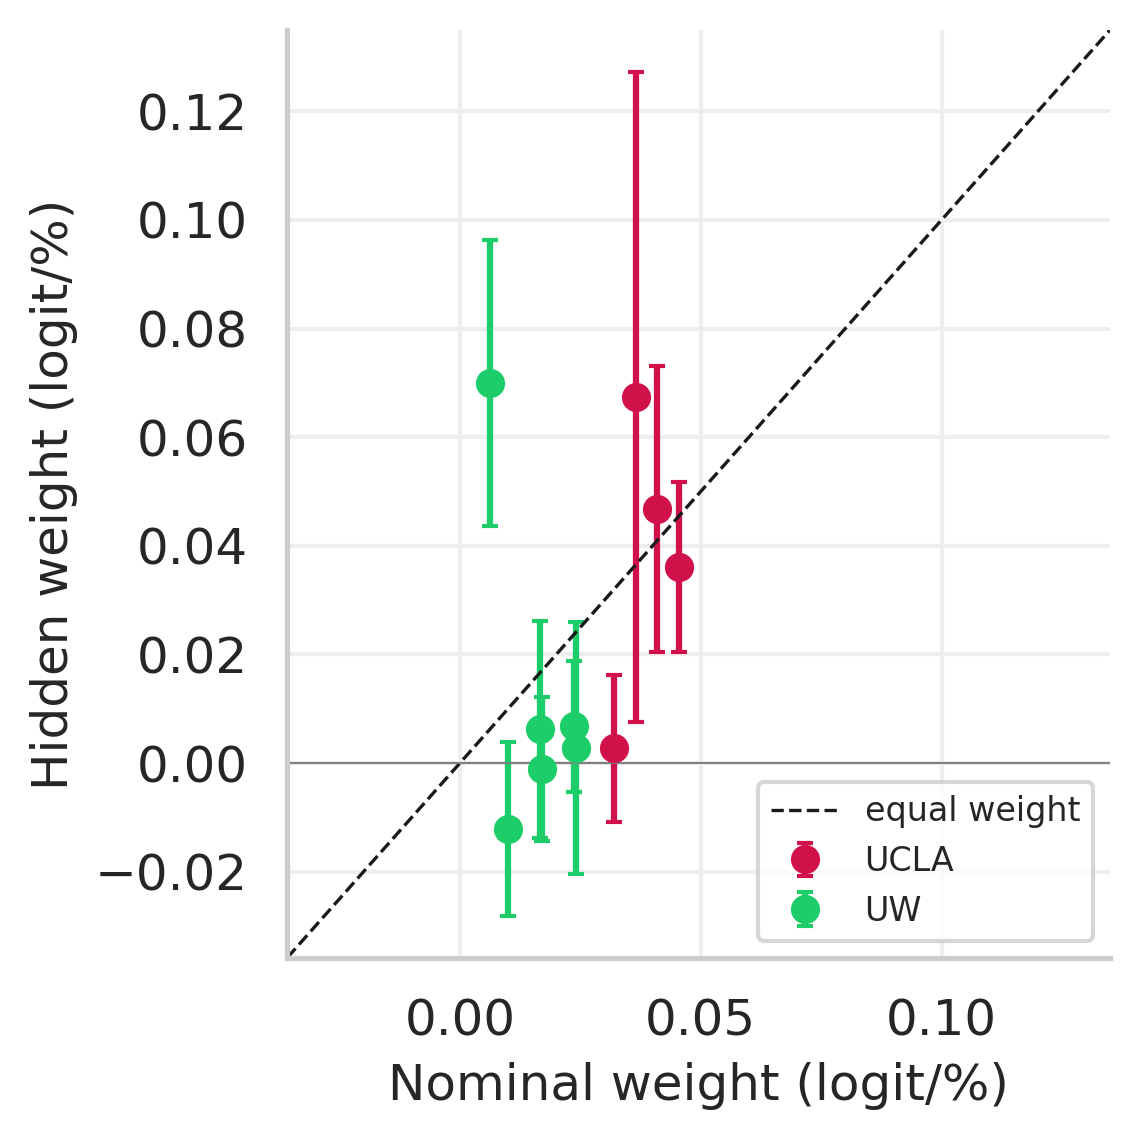

,subject_id,cohort,n,w_nominal,w_hidden,se_hidden
0,DBM12,UW,604,0.0101,-0.0121,0.0160
1,DBM13,UW,244,0.0062,0.0700,0.0263
2,DBM14,UW,299,0.0241,0.0027,0.0232
3,DBM15,UW,346,0.0166,0.0062,0.0200
4,DBM5,UW,857,0.0171,-0.0011,0.0133
5,DBM6,UW,1054,0.0237,0.0067,0.0120
6,PSUIM10,UCLA,178,0.0366,0.0674,0.0598
7,PSUIM5,UCLA,888,0.0410,0.0468,0.0263
8,PSUIM6,UCLA,2417,0.0455,0.0360,0.0156
9,PSUIM7,UCLA,2882,0.0320,0.0027,0.0135


In [14]:
weights = []
for subj, sub in controls[controls["signed_coherence"].abs() <= 36].groupby("subject_id"):
    X = sm.add_constant(sub[["signed_coherence", "hidden_coherence"]])
    fit = sm.Logit(sub["choice"], X).fit(disp=0)
    weights.append({
        "subject_id": subj,
        "cohort": sub["cohort"].iloc[0],
        "n": len(sub),
        "w_nominal": fit.params["signed_coherence"],
        "w_hidden": fit.params["hidden_coherence"],
        "se_hidden": fit.bse["hidden_coherence"],
    })
weights = pd.DataFrame(weights)

w_stat, p_pos = stats.wilcoxon(weights["w_hidden"], alternative="greater")
d_stat, p_diff = stats.wilcoxon(weights["w_hidden"] - weights["w_nominal"])
print(f"w_hidden > 0 across mice: Wilcoxon p = {p_pos:.3g}")
print(f"w_hidden vs w_nominal (paired): median difference = {np.median(weights['w_hidden'] - weights['w_nominal']):.4f}, Wilcoxon p = {p_diff:.3g}")

# Shared ratio k in "effective coherence = nominal + k * hidden", with each mouse's own intercept and slope.
# k = 1: the seed's bias is weighted exactly like programmed coherence. CI from the profile likelihood.
sub = controls[controls["signed_coherence"].abs() <= 36]
subjects = sub["subject_id"].unique()
dummies = pd.get_dummies(sub["subject_id"], dtype=float)


def profile_loglik(k):
    effective = sub["signed_coherence"] + k * sub["hidden_coherence"]
    X = pd.concat([dummies, dummies.mul(effective, axis=0).add_prefix("coh_")], axis=1)
    return sm.Logit(sub["choice"], X).fit(disp=0).llf


k_grid = np.linspace(-1, 3, 81)
loglik = np.array([profile_loglik(k) for k in k_grid])
k_hat = k_grid[np.argmax(loglik)]
k_ci = k_grid[loglik >= loglik.max() - stats.chi2.ppf(0.95, 1) / 2]
print(f"shared ratio k = {k_hat:.2f}, 95% profile CI [{k_ci.min():.2f}, {k_ci.max():.2f}] (grid step {k_grid[1] - k_grid[0]:.2f})")

fig, ax = plt.subplots(figsize=(spu.TEXTWIDTH * 0.55, spu.TEXTWIDTH * 0.55))
for cohort, color in zip(("UCLA", "UW"), ("#d11149", "#1ccd6a")):
    s = weights[weights["cohort"] == cohort]
    ax.errorbar(s["w_nominal"], s["w_hidden"], yerr=s["se_hidden"], fmt="o", color=color, label=cohort, capsize=2)
lo = min(0, (weights["w_hidden"] - weights["se_hidden"]).min())
hi = max(weights["w_nominal"].max(), (weights["w_hidden"] + weights["se_hidden"]).max())
lim = [lo - 0.05 * (hi - lo), hi + 0.05 * (hi - lo)]
ax.plot(lim, lim, "k--", lw=0.8, label="equal weight")
ax.axhline(0, color="grey", lw=0.5)
ax.set(xlim=lim, ylim=lim, xlabel="Nominal weight (logit/%)", ylabel="Hidden weight (logit/%)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
weights.round(4)

### Interpretation

- **Mice use the noise.** The hidden-coherence weight is positive in 8 of 10 mice (Wilcoxon p ≈ 0.02), so choices follow each seed's fixed bias.
- **They discount it to about half.** The shared ratio is k ≈ 0.50 (95% CI about 0.15–0.90), below 1, while the
  motion-energy model weights hidden coherence like nominal coherence (about 1.06 ME per 1%, section 5a). The discount is
  therefore in the mice, not in the energy model. Candidate explanations:
  1. *Spatial pooling.* If mice integrate only part of the screen, whole-screen hidden coherence is a noisy proxy for what
     they use, which attenuates its weight. Nominal coherence is the same everywhere on the screen and is unaffected.
     This can be tested with regional motion energy (`center`, quadrants).
  2. *Different motion sensing.* Coherent dots all move exactly horizontally, while the hidden bias is a small net
     drift of dots moving in many directions. Mouse motion detection may weight these differently from the energy model.
- **Implication for the DDM.** Feeding raw ME as evidence assumes k = 1. Allow separate gains for the nominal part and the
  residual: drift ∝ w_nom · c + w_noise · (ME − mean ME for c). Fit w_noise freely; the estimate here predicts w_noise ≈ 0.5 · w_nom.
- **Timing.** Because the noise is constant within a trial, these data say nothing about *when* evidence is weighted.
  Primacy has to come from the pulses (section 6) and the DDM.

## 6. Pulse-triggered kernels: removed (2026-10-23)

This section computed pulse-triggered, choice-conditioned kernels by pulse timing and a "primacy" amplitude slope. It was
removed because it could not measure what it claimed:
1. the residual subtracted the mean of trials that all contain the same pulse, so the pulse itself was removed and only
   choice-related noise around the pulse time remained;
2. the amplitude (`nanmax(|kernel|)`) is biased upward by noise, and differently per timing bin because later pulses
   leave fewer trials still running.

Its numbers and figure are not evidence about temporal weighting. The pulse analysis is the model-based primacy test
(`dissemination/reports/primacy-analysis-plan.md`, amendments 1-6; analysis log sections 5.9-5.11): the pre-specified
models did not predict pulse-trial behaviour (gate failed, also after the amendment 6 pulse-gain revision), so the
timing test was not run, and its calibration showed it could not detect primacy with these pulses. The old summary
figure is kept only in `dissemination/figures/superseded/`.

## 7. Summary figure: control-trial kernel

Choice-conditioned, coherence-subtracted kernel on control trials (sections 1-3). Most of this noise is a fixed per-trial
bias (section 5), so the kernel's shape does not show how evidence is weighted over time.

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(spu.TEXTWIDTH * 0.75, spu.TEXTWIDTH * 0.65))
_, _, _, mouse_mat = kernels[("residual", "stimulus_onset")]
plot_kernel_panel(ax, mouse_mat, "stimulus_onset", "Choice-conditioned kernel\n(control trials, coherence-subtracted)")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "motion_energy_kernel_control_only.png", dpi=300)
plt.savefig(FIGURE_DIR / "motion_energy_kernel_control_only.svg")
plt.show()

## Caveats / things to verify before trusting these results

- **`choice` encoding** is `1 = rightward, 0 = leftward` (checked against the sign of coherence).
- **Frame rate.** Motion energy is at 60 Hz on both rigs, so `FRAME_MS = 1000/60` applies to both. `framerate = 190`
  in `scripts/ucla_rdk.py` only scales dot velocity, and UCLA pulse durations (50-51 ms) are 3 frames at 60 Hz.
- **Filter delay.** The motion energy filters respond about 116 ms after the stimulus (methods doc, 3.2), so
  kernels are delayed relative to the stimulus, and response-aligned kernels peak earlier than the decision.
  Mention this in captions or plot against `t - ~100 ms`.
- **Residual kernel citation.** Kiani et al. 2008, Nienborg & Cumming 2009 and Okazawa et al. 2018 use 0%
  coherence trials only. Do not cite them for the residual method; compare against the 0% coherence kernel instead.
- **Section 6** (pulse-triggered kernels) was removed on 2026-10-23; see the note there.
- **Noise has no time structure.** Most motion-energy noise is a fixed per-trial bias (hidden coherence, section 5),
  so noise-based kernels cannot show how evidence is weighted over time. Use the pulses for that.
- **NaN thresholds, window sizes, and trim thresholds** (`nan_threshold`, `trim_threshold=0.4`,
  `window_frames=60`, the 200/300ms amplitude windows) are provisional choices, not fit to the data.
  Re-tune against the actual RT distribution and pulse-onset timing once real data is loaded.
- **Cluster-permutation test** is a minimal from-scratch sign-flip implementation, not a
  peer-reviewed-library implementation -- fine for exploration, but consider `mne.stats` for the version
  that ends up in a manuscript.
- **Cohort comparison (Section 4)** has only ~5 mice per cohort -- likely underpowered for anything beyond
  a rough sanity check; report it as a replication check, not a formal equivalence test.
- Trials are filtered to `reaction_time < 3000` ms (ms, after the `*1000` conversion) to match `2.13`, which
  drops 14% of trials. Revisit against the `main.yaml` acceptance criterion (`max_reaction_time`, currently 5s)
  if you want the kernel to use the full valid-trial range.